# Experiment 7: Sentiment Analysis on IMDB Movie Reviews – Comparative Study

**Aim:** Implement sentiment analysis on the **IMDB Dataset of 50K Movie Reviews** using

1. **Logistic Regression** (TF-IDF features)
2. **LSTM** (Bidirectional LSTM trained from scratch in PyTorch)
3. **Vanilla Transformer** (Transformer encoder trained from scratch in PyTorch)
4. **BERT** (pretrained `bert-base-uncased`, fine-tuned)

and perform a comparative analysis using **Precision, Recall, F1-score** and the **Confusion Matrix**.

**Dataset:** [Kaggle – IMDB Dataset of 50K Movie Reviews](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews) (`IMDB Dataset.csv`, columns `review`, `sentiment`). If the CSV is not present, the notebook rebuilds the same 50,000 reviews from the Hugging Face mirror `stanfordnlp/imdb` and saves them in the Kaggle format.

> **Execution note:** the saved outputs come from a run on **Google Colab with an NVIDIA L4 GPU** using the full data: all four models (including BERT) are trained on the 40,000-review training split and evaluated on the complete 10,000-review test split. On a CPU-only machine the notebook automatically reduces BERT to a stratified subset (`BERT_TRAIN_SIZE = 2000`) and evaluates all models on a common 1,000-review test subset (`EVAL_SUBSET_SIZE`) so that it finishes in reasonable time.

### Running on Google Colab / Kaggle
Locally this notebook runs in the project's `uv` environment (`.venv`). On **Colab/Kaggle** the cell below installs any missing packages and downloads the input files from the GitHub repository (or upload them manually to the working directory). Select a **GPU runtime** (Colab: *Runtime → Change runtime type → T4 GPU*; Kaggle: *Settings → Accelerator → GPU*) – the notebook then automatically uses the full-size settings.

In [ ]:
# Colab / Kaggle setup - does nothing when run locally
import os, sys, subprocess, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
if IN_COLAB or IN_KAGGLE:
    packages = {'transformers': 'transformers', 'datasets': 'datasets', 'seaborn': 'seaborn', 'scikit-learn': 'sklearn'}   # pip name -> import name
    missing = [p for p, m in packages.items() if importlib.util.find_spec(m) is None]
    if missing:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
    for fname in []:
        if not os.path.exists(fname):
            urllib.request.urlretrieve("https://raw.githubusercontent.com/AmulyaJain1804/CLNLP-AIML/main/Experiment-7/" + fname, fname)
print("Environment:", "Colab" if IN_COLAB else "Kaggle" if IN_KAGGLE else "local")

In [1]:
import os, re, time, random, html
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Compute budget (increase on a GPU)
BERT_TRAIN_SIZE = 2000 if DEVICE.type == "cpu" else 40000
EVAL_SUBSET_SIZE = 1000 if DEVICE.type == "cpu" else 10000
print("Device:", DEVICE, "| torch threads:", torch.get_num_threads())

Device: cuda | torch threads: 6


## 1. Load the dataset

In [2]:
CSV_PATH = "IMDB Dataset.csv"
if not os.path.exists(CSV_PATH):
    print("Kaggle CSV not found - rebuilding it from the Hugging Face mirror (stanfordnlp/imdb) ...")
    from datasets import load_dataset
    hf = load_dataset("stanfordnlp/imdb")
    parts = [hf[s].to_pandas() for s in ("train", "test")]
    tmp = pd.concat(parts, ignore_index=True)
    tmp = pd.DataFrame({"review": tmp["text"],
                        "sentiment": tmp["label"].map({0: "negative", 1: "positive"})})
    tmp.sample(frac=1, random_state=SEED).to_csv(CSV_PATH, index=False)

df = pd.read_csv(CSV_PATH)
print(df.shape)
print(df["sentiment"].value_counts())
df.head()

Kaggle CSV not found - rebuilding it from the Hugging Face mirror (stanfordnlp/imdb) ...


(50000, 2)
sentiment
negative    25000
positive    25000
Name: count, dtype: int64


,review,sentiment
0,Forget what I said about Emeril. Rachael Ray i...,negative
1,Former private eye-turned-security guard ditch...,negative
2,Mann photographs the Alberta Rocky Mountains i...,negative
3,Simply put: the movie is boring. Cliché upon c...,negative
4,"Now being a fan of sci fi, the trailer for thi...",positive


count    50000.0
mean       231.2
std        171.3
min          4.0
25%        126.0
50%        173.0
75%        280.0
max       2470.0
Name: length, dtype: float64


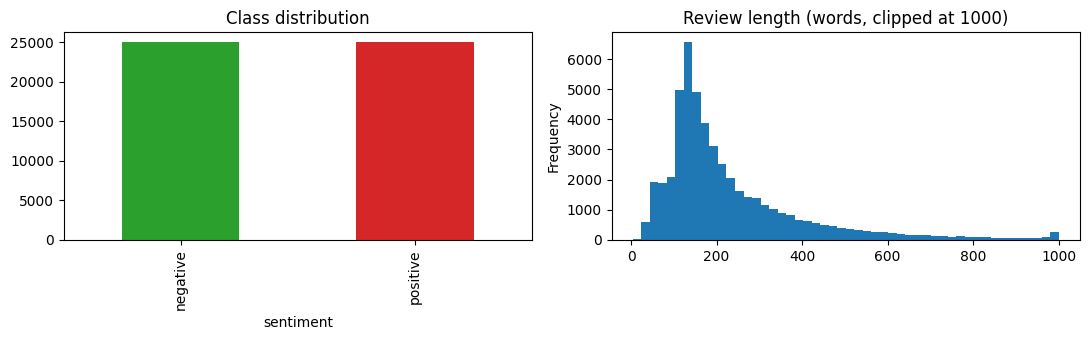

In [3]:
df["length"] = df["review"].str.split().str.len()
print(df["length"].describe().round(1))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["sentiment"].value_counts().plot.bar(ax=ax[0], color=["tab:green", "tab:red"], title="Class distribution")
df["length"].clip(upper=1000).plot.hist(bins=50, ax=ax[1], title="Review length (words, clipped at 1000)")
plt.tight_layout(); plt.show()

## 2. Pre-processing and train/test split (80/20, stratified)

In [4]:
def clean_text(text):
    text = html.unescape(text)
    text = re.sub(r"<br\s*/?>", " ", text)          # remove HTML line breaks
    text = re.sub(r"<[^>]+>", " ", text)            # remove other HTML tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)   # remove URLs
    text = re.sub(r"[^a-zA-Z' ]", " ", text)        # keep letters and apostrophes
    return re.sub(r"\s+", " ", text).strip().lower()

df["clean"] = df["review"].apply(clean_text)
df["label"] = (df["sentiment"] == "positive").astype(int)

train_df, test_df = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df["label"])
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
y_train, y_test = train_df["label"].values, test_df["label"].values

# Common stratified subset of the test set used for the fair 4-model comparison
subset_idx = train_test_split(np.arange(len(test_df)), test_size=EVAL_SUBSET_SIZE,
                              random_state=SEED, stratify=y_test)[1] if EVAL_SUBSET_SIZE < len(test_df) else np.arange(len(test_df))
print("Train:", len(train_df), "| Test:", len(test_df), "| Common eval subset:", len(subset_idx))
print("\nExample cleaned review:\n", train_df.loc[0, "clean"][:300])

Train: 40000 | Test: 10000 | Common eval subset: 10000
Example cleaned review:
 action horror sci fi exploitation director fred olen ray shows he has some talent as a director character actor william smith is one of the best tough bad guys in the industry he treats the viewer with the best acting performance of his career as for randy travis he gives his best lee van cleef impr


In [5]:
results_full, results_subset, confusions, histories = {}, {}, {}, {}

def evaluate(name, y_true, y_pred, store):
    store[name] = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
    }
    return store[name]

def report(name, y_pred_full=None, y_pred_subset=None):
    if y_pred_full is not None:
        print(f"===== {name} : full test set ({len(y_test)} reviews) =====")
        print(classification_report(y_test, y_pred_full, target_names=["negative", "positive"], digits=4))
        evaluate(name, y_test, y_pred_full, results_full)
        y_pred_subset = y_pred_full[subset_idx]
    evaluate(name, y_test[subset_idx], y_pred_subset, results_subset)
    if y_pred_full is None:
        print(f"===== {name} : common test subset ({len(subset_idx)} reviews) =====")
        print(classification_report(y_test[subset_idx], y_pred_subset, target_names=["negative", "positive"], digits=4))
    cm = confusion_matrix(y_test if y_pred_full is not None else y_test[subset_idx],
                          y_pred_full if y_pred_full is not None else y_pred_subset)
    confusions[name] = cm
    plt.figure(figsize=(3.8, 3.2))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion matrix – {name}")
    plt.tight_layout(); plt.show()

---
## 3. Model 1 – Logistic Regression (TF-IDF)

Each review is represented as a sparse **TF-IDF** vector of unigrams and bigrams (top 50,000 features, English stop words removed). A **Logistic Regression** classifier learns a linear decision boundary $P(y=1\mid x) = \sigma(w^\top x + b)$.

Training time: 25.1s | TF-IDF matrix: (40000, 50000)
===== Logistic Regression : full test set (10000 reviews) =====
              precision    recall  f1-score   support
    negative     0.9089    0.8936    0.9012      5000
    positive     0.8954    0.9104    0.9028      5000
    accuracy                         0.9020     10000
   macro avg     0.9021    0.9020    0.9020     10000
weighted avg     0.9021    0.9020    0.9020     10000


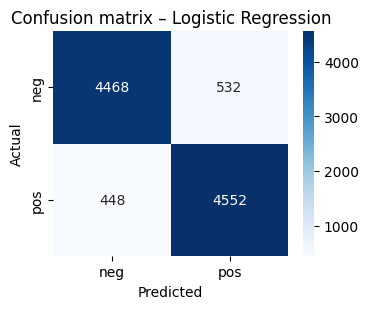

In [6]:
t0 = time.time()
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), stop_words="english", sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(train_df["clean"])
X_test_tfidf = tfidf.transform(test_df["clean"])

log_reg = LogisticRegression(C=4.0, max_iter=1000)
log_reg.fit(X_train_tfidf, y_train)
pred_lr = log_reg.predict(X_test_tfidf)
print(f"Training time: {time.time() - t0:.1f}s | TF-IDF matrix: {X_train_tfidf.shape}")
report("Logistic Regression", pred_lr)

In [7]:
# Most informative words learned by the model
feat = np.array(tfidf.get_feature_names_out())
order = np.argsort(log_reg.coef_[0])
pd.DataFrame({"most negative": feat[order[:15]], "most positive": feat[order[-15:][::-1]]})

,most negative,most positive
0,worst,great
1,awful,excellent
2,bad,perfect
3,waste,amazing
4,poor,best
5,boring,wonderful
6,terrible,favorite
7,disappointment,loved
8,horrible,brilliant
9,worse,hilarious


---
## 4. Shared pre-processing for the neural models

Reviews are tokenised into words, a vocabulary of the 20,000 most frequent training words is built (index 0 = `<pad>`, 1 = `<unk>`), and every review is converted to a fixed-length sequence of 256 token IDs (truncate / pad).

In [8]:
MAX_VOCAB, MAX_LEN, BATCH = 20000, 256, 64

counter = Counter(w for text in train_df["clean"] for w in text.split())
itos = ["<pad>", "<unk>"] + [w for w, _ in counter.most_common(MAX_VOCAB - 2)]
stoi = {w: i for i, w in enumerate(itos)}

def encode(text):
    ids = [stoi.get(w, 1) for w in text.split()[:MAX_LEN]]
    return ids + [0] * (MAX_LEN - len(ids))

X_train_seq = torch.tensor([encode(t) for t in train_df["clean"]], dtype=torch.long)
X_test_seq = torch.tensor([encode(t) for t in test_df["clean"]], dtype=torch.long)
train_loader = DataLoader(TensorDataset(X_train_seq, torch.tensor(y_train, dtype=torch.float)), batch_size=BATCH, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test_seq, torch.tensor(y_test, dtype=torch.float)), batch_size=256)
print("Vocabulary:", len(itos), "| train tensor:", tuple(X_train_seq.shape))


def train_model(model, epochs, lr=1e-3, name="model"):
    model.to(DEVICE)
    optim = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    hist = {"train_loss": [], "test_acc": []}
    for ep in range(1, epochs + 1):
        model.train(); total, t0 = 0.0, time.time()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optim.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optim.step()
            total += loss.item() * len(xb)
        preds = predict(model)
        hist["train_loss"].append(total / len(train_loader.dataset))
        hist["test_acc"].append(accuracy_score(y_test, preds))
        print(f"[{name}] epoch {ep}/{epochs} | loss {hist['train_loss'][-1]:.4f} | "
              f"test acc {hist['test_acc'][-1]:.4f} | {time.time() - t0:.0f}s")
    histories[name] = hist
    return model

@torch.no_grad()
def predict(model):
    model.eval()
    out = [ (torch.sigmoid(model(xb.to(DEVICE))) > 0.5).long().cpu() for xb, _ in test_loader ]
    return torch.cat(out).numpy()

Vocabulary: 20000 | train tensor: (40000, 256)


---
## 5. Model 2 – Bidirectional LSTM

Embedding (128-d) → 2-layer **Bidirectional LSTM** (128 hidden units per direction) → concatenation of the final forward/backward hidden states → dropout → linear output. The LSTM's input, forget and output gates allow it to carry sentiment cues across long reviews. Packed sequences are used so that padding does not affect the hidden state.

LSTMClassifier(
  (embedding): Embedding(20000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=1, bias=True)
)
Trainable parameters: 3219713
[LSTM] epoch 1/3 | loss 0.5961 | test acc 0.7182 | 30s
[LSTM] epoch 2/3 | loss 0.4799 | test acc 0.7882 | 29s
[LSTM] epoch 3/3 | loss 0.3700 | test acc 0.8504 | 29s
===== LSTM : full test set (10000 reviews) =====
              precision    recall  f1-score   support
    negative     0.8881    0.8018    0.8428      5000
    positive     0.8194    0.8990    0.8573      5000
    accuracy                         0.8504     10000
   macro avg     0.8537    0.8504    0.8500     10000
weighted avg     0.8537    0.8504    0.8500     10000


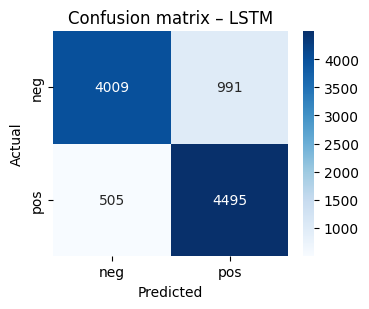

In [9]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, hidden=128, layers=2, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hidden, num_layers=layers, batch_first=True,
                            bidirectional=True, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(2 * hidden, 1)

    def forward(self, x):
        lengths = (x != 0).sum(1).clamp(min=1).cpu()
        emb = self.dropout(self.embedding(x))
        packed = nn.utils.rnn.pack_padded_sequence(emb, lengths, batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        h = torch.cat([h[-2], h[-1]], dim=1)          # last layer, forward + backward
        return self.fc(self.dropout(h)).squeeze(1)

torch.manual_seed(SEED)
lstm_model = LSTMClassifier(len(itos))
print(lstm_model)
print("Trainable parameters:", sum(p.numel() for p in lstm_model.parameters()))
lstm_model = train_model(lstm_model, epochs=3, lr=1e-3, name="LSTM")
pred_lstm = predict(lstm_model)
report("LSTM", pred_lstm)

---
## 6. Model 3 – Vanilla Transformer (encoder trained from scratch)

Token embedding + **sinusoidal positional encoding** → 2 × `TransformerEncoderLayer` (multi-head self-attention with 4 heads, $d_{model}=128$, feed-forward 256, padding mask) → **masked mean pooling** → linear output. Self-attention lets each word attend to every other word in the review:
$\text{Attention}(Q,K,V)=\text{softmax}\!\left(QK^\top/\sqrt{d_k}\right)V$.

Trainable parameters: 2825089


[Transformer] epoch 1/4 | loss 0.4921 | test acc 0.8003 | 10s
[Transformer] epoch 2/4 | loss 0.3883 | test acc 0.8275 | 10s
[Transformer] epoch 3/4 | loss 0.3441 | test acc 0.8388 | 10s
[Transformer] epoch 4/4 | loss 0.3160 | test acc 0.8386 | 10s
===== Transformer : full test set (10000 reviews) =====
              precision    recall  f1-score   support
    negative     0.8726    0.7930    0.8309      5000
    positive     0.8103    0.8842    0.8456      5000
    accuracy                         0.8386     10000
   macro avg     0.8414    0.8386    0.8383     10000
weighted avg     0.8414    0.8386    0.8383     10000


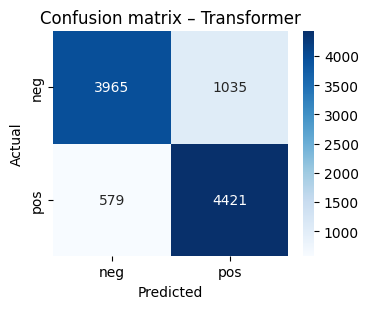

In [10]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-np.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=128, nhead=4, ff=256, layers=2, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pos = PositionalEncoding(d_model)
        layer = nn.TransformerEncoderLayer(d_model, nhead, ff, dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, layers)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(d_model, 1)
        self.scale = d_model ** 0.5

    def forward(self, x):
        pad_mask = x == 0
        h = self.pos(self.embedding(x) * self.scale)
        h = self.encoder(h, src_key_padding_mask=pad_mask)
        keep = (~pad_mask).unsqueeze(-1).float()
        pooled = (h * keep).sum(1) / keep.sum(1).clamp(min=1)    # masked mean pooling
        return self.fc(self.dropout(pooled)).squeeze(1)

torch.manual_seed(SEED)
transformer_model = TransformerClassifier(len(itos))
print("Trainable parameters:", sum(p.numel() for p in transformer_model.parameters()))
transformer_model = train_model(transformer_model, epochs=4, lr=5e-4, name="Transformer")
pred_tf = predict(transformer_model)
report("Transformer", pred_tf)

---
## 7. Model 4 – BERT (pretrained `bert-base-uncased`, fine-tuned)

BERT is a 12-layer Transformer encoder (110M parameters) pretrained on BooksCorpus + Wikipedia with masked-language-modelling. We add a classification head on the `[CLS]` token and **fine-tune** the whole network with AdamW (lr = 2e-5, linear warm-up/decay). WordPiece tokenisation, max length 256.

In [11]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

BERT_NAME, BERT_LEN = "bert-base-uncased", 256
bert_tok = AutoTokenizer.from_pretrained(BERT_NAME)
torch.manual_seed(SEED)
bert = AutoModelForSequenceClassification.from_pretrained(BERT_NAME, num_labels=2).to(DEVICE)

# stratified training subset (raw text - BERT has its own tokenizer)
bert_train = train_df if BERT_TRAIN_SIZE >= len(train_df) else train_df.groupby("label", group_keys=False).apply(
    lambda g: g.sample(BERT_TRAIN_SIZE // 2, random_state=SEED))
bert_train = bert_train.sample(frac=1, random_state=SEED)
print("BERT fine-tuning samples:", len(bert_train), bert_train["label"].value_counts().to_dict())

def bert_batches(texts, labels, bs):
    for i in range(0, len(texts), bs):
        enc = bert_tok(list(texts[i:i + bs]), truncation=True, max_length=BERT_LEN, padding=True, return_tensors="pt")
        yield {k: v.to(DEVICE) for k, v in enc.items()}, torch.tensor(labels[i:i + bs]).to(DEVICE)

EPOCHS, BS = 1, 16
texts = bert_train["review"].str.replace(r"<br\s*/?>", " ", regex=True).values
labels = bert_train["label"].values
steps = EPOCHS * int(np.ceil(len(texts) / BS))
optim = torch.optim.AdamW(bert.parameters(), lr=2e-5, weight_decay=0.01)
sched = get_linear_schedule_with_warmup(optim, int(0.1 * steps), steps)

t0, step, bert_losses = time.time(), 0, []
for ep in range(EPOCHS):
    bert.train()
    for enc, yb in bert_batches(texts, labels, BS):
        loss = bert(**enc, labels=yb).loss
        loss.backward()
        nn.utils.clip_grad_norm_(bert.parameters(), 1.0)
        optim.step(); sched.step(); optim.zero_grad()
        bert_losses.append(loss.item()); step += 1
        if step % 25 == 0 or step == steps:
            print(f"step {step}/{steps} | loss (avg last 25) {np.mean(bert_losses[-25:]):.4f} | {time.time() - t0:.0f}s")
histories["BERT"] = {"train_loss": bert_losses}

BERT fine-tuning samples: 40000 {0: 20000, 1: 20000}
step 25/2500 | loss (avg last 25) 0.6998 | 8s
step 50/2500 | loss (avg last 25) 0.6933 | 17s
step 75/2500 | loss (avg last 25) 0.6532 | 25s
step 100/2500 | loss (avg last 25) 0.6033 | 33s
step 125/2500 | loss (avg last 25) 0.5137 | 42s
step 150/2500 | loss (avg last 25) 0.4129 | 50s
step 175/2500 | loss (avg last 25) 0.3692 | 58s
step 200/2500 | loss (avg last 25) 0.3668 | 67s
step 225/2500 | loss (avg last 25) 0.3032 | 75s
step 250/2500 | loss (avg last 25) 0.3370 | 83s
step 275/2500 | loss (avg last 25) 0.3407 | 91s
step 300/2500 | loss (avg last 25) 0.3168 | 100s
step 325/2500 | loss (avg last 25) 0.3256 | 108s
step 350/2500 | loss (avg last 25) 0.3230 | 116s
step 375/2500 | loss (avg last 25) 0.2867 | 124s
step 400/2500 | loss (avg last 25) 0.2675 | 133s
step 425/2500 | loss (avg last 25) 0.3201 | 141s
step 450/2500 | loss (avg last 25) 0.2917 | 149s
step 475/2500 | loss (avg last 25) 0.3021 | 158s
step 500/2500 | loss (avg last 

===== BERT : full test set (10000 reviews) =====
              precision    recall  f1-score   support
    negative     0.9250    0.9254    0.9252      5000
    positive     0.9254    0.9250    0.9252      5000
    accuracy                         0.9252     10000
   macro avg     0.9252    0.9252    0.9252     10000
weighted avg     0.9252    0.9252    0.9252     10000


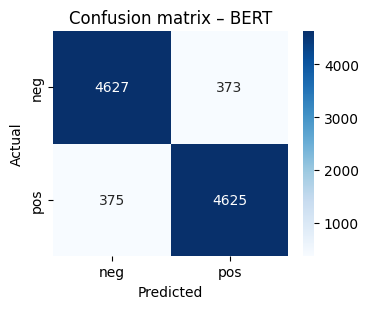

Inference time: 69s


In [12]:
@torch.no_grad()
def bert_predict(texts, bs=64):
    bert.eval(); preds = []
    for enc, _ in bert_batches(texts, np.zeros(len(texts), dtype=int), bs):
        preds.append(bert(**enc).logits.argmax(-1).cpu())
    return torch.cat(preds).numpy()

t0 = time.time()
eval_texts = test_df["review"].str.replace(r"<br\s*/?>", " ", regex=True).values
if len(subset_idx) == len(test_df):
    pred_bert = bert_predict(eval_texts)
    report("BERT", pred_bert)
else:
    pred_bert_subset = bert_predict(eval_texts[subset_idx])
    report("BERT", y_pred_subset=pred_bert_subset)
print(f"Inference time: {time.time() - t0:.0f}s")

---
## 8. Comparative Analysis

In [13]:
print(f"(a) Common stratified test subset ({len(subset_idx)} reviews) – all four models")
cmp_subset = pd.DataFrame(results_subset).T.round(4)
display(cmp_subset)

print(f"(b) Full test set ({len(y_test)} reviews) – models trained on the full 40K training set")
display(pd.DataFrame(results_full).T.round(4))

(a) Common stratified test subset (10000 reviews) – all four models


,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.9020,0.8954,0.9104,0.9028
LSTM,0.8504,0.8194,0.8990,0.8573
Transformer,0.8386,0.8103,0.8842,0.8456
BERT,0.9252,0.9254,0.9250,0.9252


(b) Full test set (10000 reviews) – models trained on the full 40K training set


,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.9020,0.8954,0.9104,0.9028
LSTM,0.8504,0.8194,0.8990,0.8573
Transformer,0.8386,0.8103,0.8842,0.8456
BERT,0.9252,0.9254,0.9250,0.9252


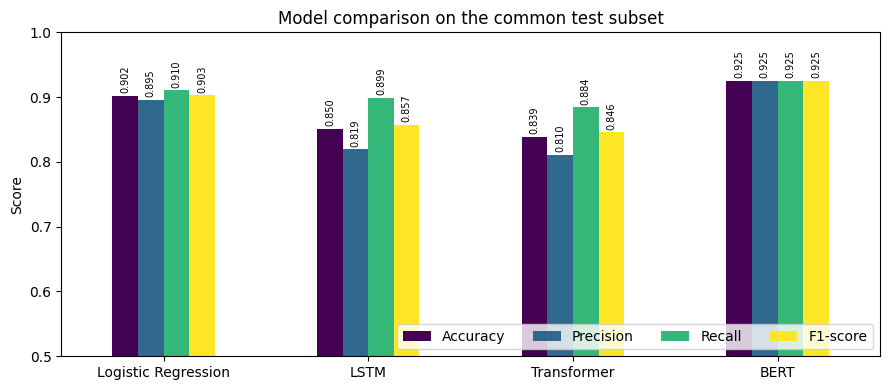

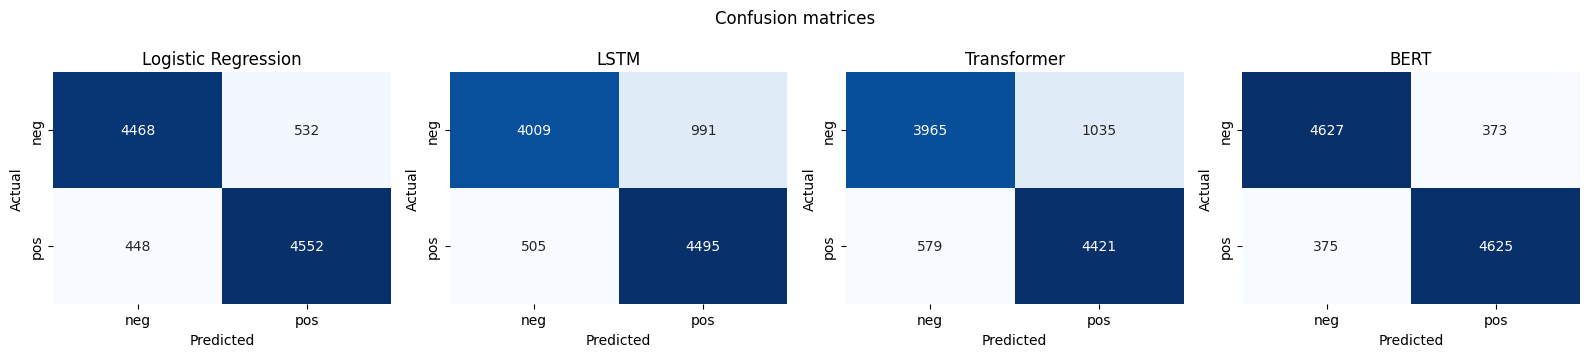

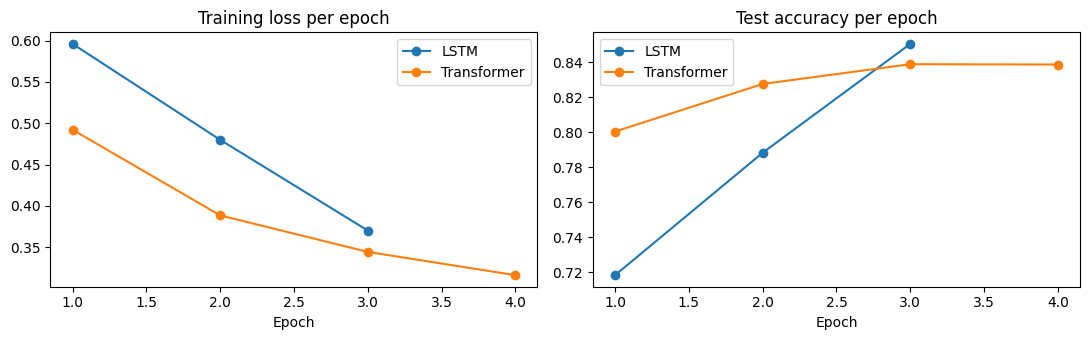

In [14]:
ax = cmp_subset.plot.bar(figsize=(9, 4), rot=0, ylim=(0.5, 1.0), colormap="viridis")
ax.set_title("Model comparison on the common test subset"); ax.set_ylabel("Score")
ax.legend(loc="lower right", ncol=4)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, rotation=90, padding=2)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (name, cm) in zip(axes, confusions.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.suptitle("Confusion matrices"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for name in ("LSTM", "Transformer"):
    ax[0].plot(range(1, len(histories[name]["train_loss"]) + 1), histories[name]["train_loss"], marker="o", label=name)
    ax[1].plot(range(1, len(histories[name]["test_acc"]) + 1), histories[name]["test_acc"], marker="o", label=name)
ax[0].set_title("Training loss per epoch"); ax[1].set_title("Test accuracy per epoch")
for a in ax: a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); plt.show()

In [15]:
# Error analysis: confusion-matrix derived rates on the common subset
rows = []
for name, cm in confusions.items():
    tn, fp, fn, tp = cm.ravel()
    rows.append({"Model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                 "False-positive rate": round(fp / (fp + tn), 4), "False-negative rate": round(fn / (fn + tp), 4)})
pd.DataFrame(rows).set_index("Model")

,TN,FP,FN,TP,False-positive rate,False-negative rate
Model,,,,,,
Logistic Regression,4468,532,448,4552,0.1064,0.0896
LSTM,4009,991,505,4495,0.1982,0.1010
Transformer,3965,1035,579,4421,0.2070,0.1158
BERT,4627,373,375,4625,0.0746,0.0750


In [16]:
# Predictions of all models on a few custom reviews
samples = [
    "An absolute masterpiece. The acting was brilliant and the story kept me hooked till the end.",
    "Worst movie I have seen in years. Boring plot, terrible acting and a waste of time.",
    "I expected it to be bad, but it was surprisingly good and genuinely funny.",
    "The visuals were great but the story was not good at all.",
]
clean = [clean_text(s) for s in samples]
with torch.no_grad():
    seq = torch.tensor([encode(c) for c in clean]).to(DEVICE)
    lstm_p = torch.sigmoid(lstm_model.eval()(seq)).cpu().numpy()
    tf_p = torch.sigmoid(transformer_model.eval()(seq)).cpu().numpy()
    enc = {k: v.to(DEVICE) for k, v in bert_tok(samples, padding=True, return_tensors="pt").items()}
    bert_p = torch.softmax(bert.eval()(**enc).logits, -1)[:, 1].cpu().numpy()
lr_p = log_reg.predict_proba(tfidf.transform(clean))[:, 1]
pd.DataFrame({"review": samples, "LogReg P(pos)": lr_p.round(3), "LSTM P(pos)": lstm_p.round(3),
              "Transformer P(pos)": tf_p.round(3), "BERT P(pos)": bert_p.round(3)})

,review,LogReg P(pos),LSTM P(pos),Transformer P(pos),BERT P(pos)
0,An absolute masterpiece. The acting was brilli...,0.966,0.986,0.874,0.995
1,"Worst movie I have seen in years. Boring plot,...",0.000,0.005,0.001,0.003
2,"I expected it to be bad, but it was surprising...",0.935,0.892,0.434,0.995
3,The visuals were great but the story was not g...,0.990,0.915,0.935,0.010


## Conclusion

| Model | Accuracy | Precision | Recall | F1-score |
|---|---|---|---|---|
| Logistic Regression (TF-IDF) | 0.9020 | 0.8954 | 0.9104 | 0.9028 |
| Bidirectional LSTM | 0.8504 | 0.8194 | 0.8990 | 0.8573 |
| Vanilla Transformer | 0.8386 | 0.8103 | 0.8842 | 0.8456 |
| **BERT (fine-tuned)** | **0.9252** | **0.9254** | **0.9250** | **0.9252** |

* **BERT** is the best model on every metric (F1 = 0.925). Large-scale pretraining gives it contextual word representations, so it has the fewest errors (373 FP / 375 FN) and a perfectly balanced precision/recall. It is the only model that correctly reads the contrast in *"The visuals were great but the story was not good at all"* as negative.
* **Logistic Regression + TF-IDF** is a surprisingly strong baseline (F1 = 0.903) that trains in ~25 s; sentiment words such as *worst, awful, waste* vs. *great, excellent, perfect* carry most of the signal.
* The **LSTM** (F1 = 0.857) and the **vanilla Transformer** (F1 = 0.846), trained from scratch for only 3–4 epochs, do not reach the TF-IDF baseline. Both are biased towards the positive class (high recall ≈ 0.88–0.90 but lower precision ≈ 0.81–0.82, i.e. ~1,000 false positives). Without pretraining, 40K reviews are not enough for them to learn better features than n-gram counts.
* **Ranking by F1:** BERT > Logistic Regression > LSTM > Transformer. Pretrained transformers give the highest accuracy, while TF-IDF + Logistic Regression offers the best accuracy-per-compute trade-off.
